In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats

In [27]:
folder_path = '/content/drive/MyDrive/Agricultural_Drought_Lampung'

file_spi = os.path.join(folder_path, 'SPI3_Monthly_Statistics_Historical_1981_2025.csv')
file_vci = os.path.join(folder_path, 'MODIS_VCI_Comparative_Statistics_2015_2025.csv')

# Load CSV
df_spi = pd.read_csv(file_spi)
df_vci = pd.read_csv(file_vci)

print("Dataset SPI-3 loaded:", df_spi.shape)
print("Dataset VCI loaded:", df_vci.shape)

Dataset SPI-3 loaded: (540, 10)
Dataset VCI loaded: (132, 8)


In [28]:
# Filter SPI-3 khusus periode analisis MODIS (2015–2025)
df_spi_filtered = df_spi[(df_spi['year'] >= 2015) & (df_spi['year'] <= 2025)].copy()

# Penggabungan tabel berdasarkan Year dan Month
df_merged = pd.merge(
    df_vci,
    df_spi_filtered[['year', 'month', 'SPI3_mean', 'SPI3_min', 'SPI3_max']],
    on=['year', 'month'],
    how='inner'
)

# Menambahkan kolom Datetime (convert year and month to int first to avoid decimals)
df_merged['date'] = pd.to_datetime(
    df_merged['year'].astype(int).astype(str) + '-' + df_merged['month'].astype(int).astype(str).str.zfill(2) + '-01'
)

# Sort berdasarkan tanggal
df_merged = df_merged.sort_values('date').reset_index(drop=True)

print("\n--- Summary Merged Dataset (2015-2025) ---")
print(df_merged[['date', 'SPI3_mean', 'VCI_Cropland_mean', 'VCI_All_mean']].head())


--- Summary Merged Dataset (2015-2025) ---
        date  SPI3_mean  VCI_Cropland_mean  VCI_All_mean
0 2015-01-01  -0.289093          60.737931     56.540197
1 2015-02-01  -0.278621          56.355083     56.100230
2 2015-03-01   0.188829          61.882407     61.856696
3 2015-04-01  -0.356478          64.053910     61.271823
4 2015-05-01   0.692985          56.104334     54.807770


In [29]:
# Menghitung korelasi Pearson & Spearman pada Lag 0, 1, 2, dan 3 bulan
lags = [0, 1, 2, 3]
lag_results = []

for lag in lags:
    # Geser SPI-3 sebanyak lag bulan
    spi_shifted = df_merged['SPI3_mean'].shift(lag)
    vci_crop = df_merged['VCI_Cropland_mean']

    # Hapus baris NaN akibat shifting
    valid_idx = spi_shifted.notna() & vci_crop.notna()

    r_pearson, p_pearson = stats.pearsonr(spi_shifted[valid_idx], vci_crop[valid_idx])
    r_spearman, p_spearman = stats.spearmanr(spi_shifted[valid_idx], vci_crop[valid_idx])

    lag_results.append({
        'Lag (Bulan)': f'Lag {lag}',
        'Pearson r': round(r_pearson, 3),
        'Pearson p-value': round(p_pearson, 4),
        'Spearman r': round(r_spearman, 3),
        'Spearman p-value': round(p_spearman, 4)
    })

df_lag = pd.DataFrame(lag_results)

print("  Hasil Analisis Korelasi Lag (SPI-3 vs VCI PERTANIAN)  ")
print("------------------------------------------------------")
print(df_lag.to_string(index=False))

# Identifikasi Lag Tertinggi
best_lag_row = df_lag.loc[df_lag['Pearson r'].idxmax()]
print(f"\nKesimpulan Lag: Korelasi terkuat ditemukan pada {best_lag_row['Lag (Bulan)']} (r = {best_lag_row['Pearson r']}).")

  Hasil Analisis Korelasi Lag (SPI-3 vs VCI PERTANIAN)  
------------------------------------------------------
Lag (Bulan)  Pearson r  Pearson p-value  Spearman r  Spearman p-value
      Lag 0     -0.623           0.0000      -0.579            0.0000
      Lag 1     -0.494           0.0000      -0.456            0.0000
      Lag 2     -0.327           0.0001      -0.290            0.0008
      Lag 3     -0.157           0.0763      -0.133            0.1341

Kesimpulan Lag: Korelasi terkuat ditemukan pada Lag 3 (r = -0.157).


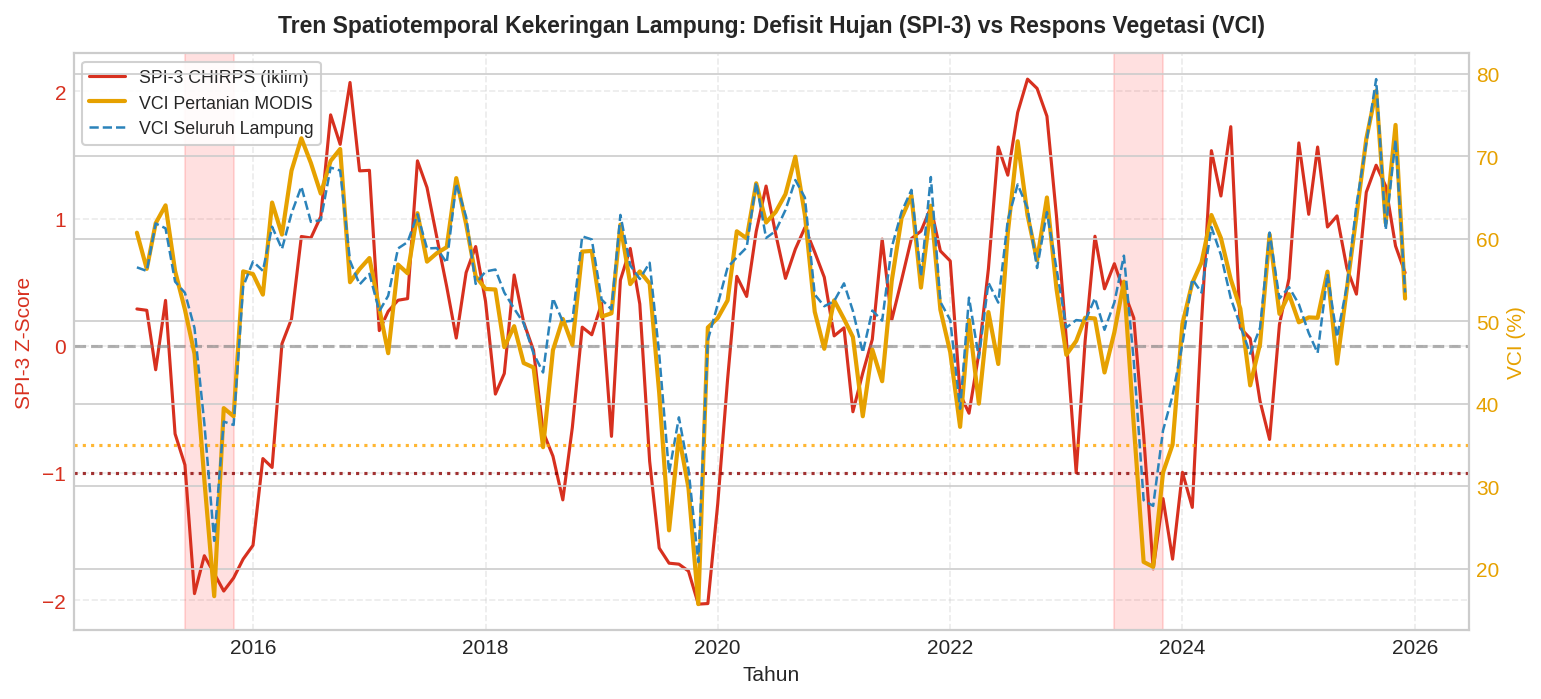

In [30]:
df_plot = df_merged.copy()
df_plot['SPI3_mean'] = df_plot['SPI3_mean'] * -1


# Grafik 1: DUAL-AXIS TIME-SERIES (SPI-3 vs VCI)
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 5), dpi=150)
ax2 = ax1.twinx()

# Plot Line 1: SPI-3
line1 = ax1.plot(df_plot['date'], df_plot['SPI3_mean'], color='#d7301f', linewidth=1.5, label='SPI-3 CHIRPS (Iklim)')
ax1.axhline(0, color='gray', linestyle='--', alpha=0.6)
ax1.axhline(-1, color='darkred', linestyle=':', alpha=0.8, label='Batas Kering SPI-3 (< -1)')

# Plot Line 2 & 3: VCI
line2 = ax2.plot(df_plot['date'], df_plot['VCI_Cropland_mean'], color='#e6a100', linewidth=2.0, label='VCI Pertanian MODIS')
line3 = ax2.plot(df_plot['date'], df_plot['VCI_All_mean'], color='#2b83ba', linewidth=1.2, linestyle='--', label='VCI Seluruh Lampung')
ax2.axhline(35, color='orange', linestyle=':', alpha=0.8, label='Batas Stres VCI (< 35%)')

# Highlight Periode El Niño 2015 & 2023
ax1.axvspan(pd.to_datetime('2015-06-01'), pd.to_datetime('2015-11-01'), color='red', alpha=0.12, label='El Niño 2015')
ax1.axvspan(pd.to_datetime('2023-06-01'), pd.to_datetime('2023-11-01'), color='red', alpha=0.12, label='El Niño 2023')

# Label & Judul
ax1.set_title('Tren Spatiotemporal Kekeringan Lampung: Defisit Hujan (SPI-3) vs Respons Vegetasi (VCI)', fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel('Tahun', fontsize=10)
ax1.set_ylabel('SPI-3 Z-Score', fontsize=10, color='#d7301f')
ax2.set_ylabel('VCI (%)', fontsize=10, color='#e6a100')

ax1.tick_params(axis='y', labelcolor='#d7301f')
ax2.tick_params(axis='y', labelcolor='#e6a100')
ax1.grid(True, linestyle='--', alpha=0.4)

# Legenda Gabungan
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)

# Simpan & Tampilkan
fig1_path = os.path.join(folder_path, 'SPI3_VCI_TimeSeries.png')
plt.savefig(fig1_path, dpi=300)
plt.show()

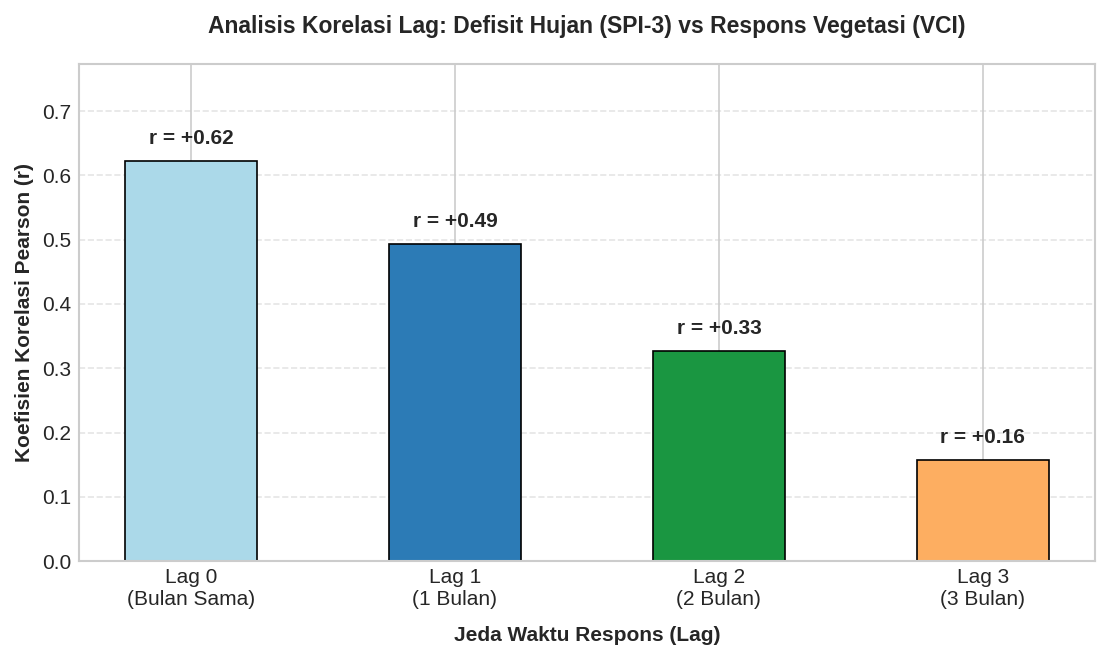

File gambar korelasi lag yang baru berhasil disimpan: /content/drive/MyDrive/Agricultural_Drought_Lampung/SPI3_VCI_Lag_Correlation.png


In [38]:
import matplotlib.pyplot as plt
import os

# KORELASI LAG (SPI-3 vs VCI)

lags = ['Lag 0\n(Bulan Sama)', 'Lag 1\n(1 Bulan)', 'Lag 2\n(2 Bulan)', 'Lag 3\n(3 Bulan)']

# Mengambil nilai Pearson r secara dinamis lalu diubah menjadi positif (absolut)
correlations = [abs(val) for val in df_lag['Pearson r'].tolist()]

plt.figure(figsize=(7.5, 4.5), dpi=150)
colors = ['#abd9e9', '#2c7bb6', '#1a9641', '#fdae61']
bars = plt.bar(lags, correlations, color=colors, width=0.5, edgecolor='black', linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    # Label nilai r positif tepat di atas setiap batang
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'r = +{yval:.2f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Dekorasi & Judul
plt.title('Analisis Korelasi Lag: Defisit Hujan (SPI-3) vs Respons Vegetasi (VCI)', fontsize=11, fontweight='bold', pad=15)
plt.xlabel('Jeda Waktu Respons (Lag)', fontsize=10, fontweight='bold', labelpad=8)
plt.ylabel('Koefisien Korelasi Pearson (r)', fontsize=10, fontweight='bold')

# Batas sumbu Y mulai dari 0 hingga sedikit di atas nilai maksimum
plt.ylim(0, max(correlations) + 0.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Tight layout & Simpan Ulang
plt.tight_layout()
output_lag_path = os.path.join(folder_path, 'SPI3_VCI_Lag_Correlation.png')
plt.savefig(output_lag_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"File gambar korelasi lag yang baru berhasil disimpan: {output_lag_path}")

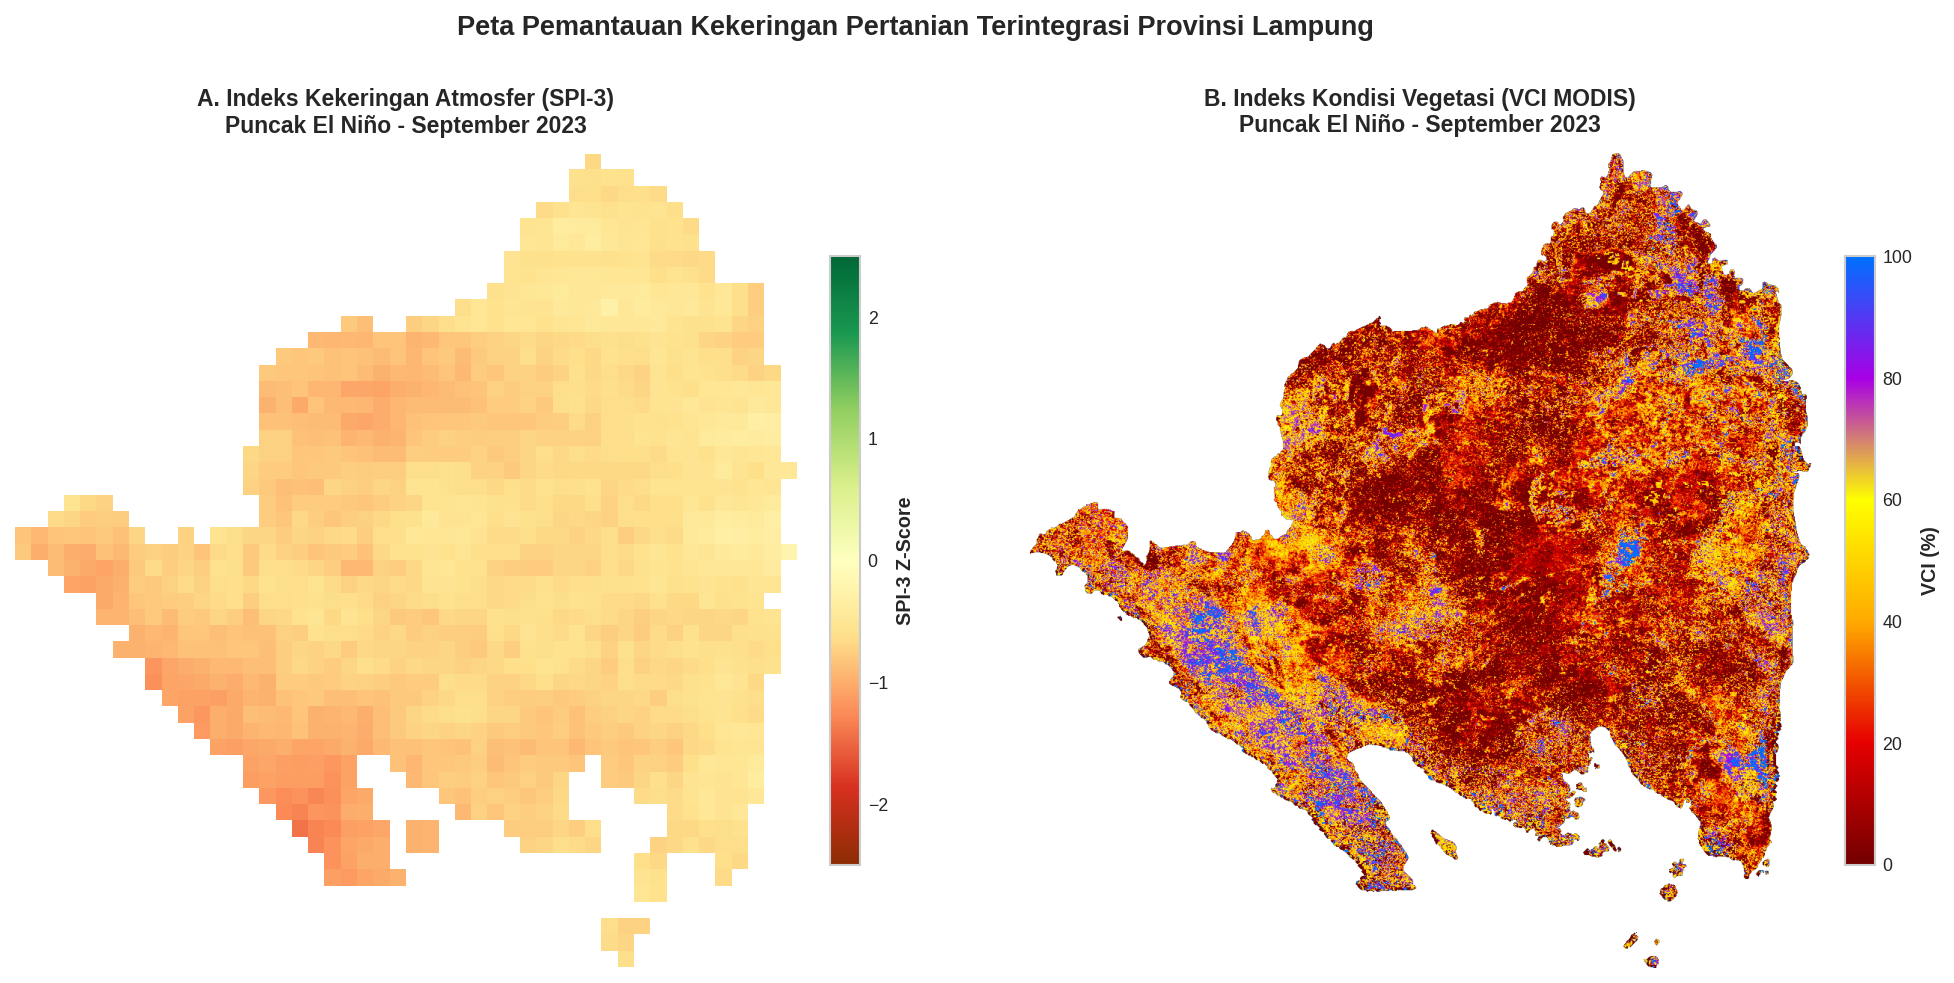


Peta spasial berhasil disimpan ke Drive: /content/drive/MyDrive/Agricultural_Drought_Lampung/Integrated_Drought_Map_Sept2023.png


In [32]:
try:
  import rasterio
except ImportError:
  !pip install rasterio
  import rasterio

# Setup Path & Identifikasi Band (September 2023)
folder_path = '/content/drive/MyDrive/Agricultural_Drought_Lampung'

file_tif_spi = os.path.join(folder_path, 'SPI3_Monthly_Stack_2015_2025.tif')
file_tif_vci = os.path.join(
    folder_path, 'MODIS_VCI_AllVegetation_Stack_2015_2025.tif'
)

# Menentukan indeks band untuk September 2023
# Urutan: (2023 - 2015) * 12 + 9 = 8 * 12 + 9 = Band ke-105 (1-based index)
band_sept_2023 = (2023 - 2015) * 12 + 9

# Baca Raster GeoTiff
with rasterio.open(file_tif_spi) as src_spi:
  # Balikkan tanda SPI-3 (-1) agar negatif = Kering
  grid_spi = src_spi.read(band_sept_2023) * -1
  # Masking nodata/invalid pixels
  grid_spi = np.where(grid_spi < -10, np.nan, grid_spi)

with rasterio.open(file_tif_vci) as src_vci:
  grid_vci = src_vci.read(band_sept_2023)
  grid_vci = np.where((grid_vci < 0) | (grid_vci > 100), np.nan, grid_vci)


# Setup Palet Warna (Colormaps)
# Palet SPI-3: Merah Tua (Kering Ekstrem) -> Kuning -> Hijau Tua (Basah)
cmap_spi = mcolors.LinearSegmentedColormap.from_list(
    'spi_cmap',
    [
        '#8c2d04',
        '#d7301f',
        '#fc8d59',
        '#fee08b',
        '#ffffbf',
        '#d9ef8b',
        '#91cf60',
        '#1a9850',
        '#006837',
    ],
)

# Palet VCI: Cokelat Merah (Stres Ekstrem) -> Oranye -> Kuning -> Biru (Sehat)
cmap_vci = mcolors.LinearSegmentedColormap.from_list(
    'vci_cmap',
    ['#730000', '#e60000', '#ffaa00', '#ffff00', '#a800e6', '#0070ff'],
)

# Plotting Maps Side-By-Side (September 2023)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5), dpi=150)

# PETA 1: SPI-3 CHIRPS (ATMOSPHERIC DROUGHT)
im1 = ax1.imshow(grid_spi, cmap=cmap_spi, vmin=-2.5, vmax=2.5)
ax1.set_title(
    'A. Indeks Kekeringan Atmosfer (SPI-3)\nPuncak El Niño - September 2023',
    fontsize=11,
    fontweight='bold',
    pad=10,
)
ax1.axis('off')

# Colorbar SPI-3
cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.036, pad=0.04)
cbar1.set_label('SPI-3 Z-Score', fontsize=9.5, fontweight='bold')
cbar1.ax.tick_params(labelsize=8.5)

# PETA 2: VCI MODIS (VEGETATION RESPONSE)
im2 = ax2.imshow(grid_vci, cmap=cmap_vci, vmin=0, vmax=100)
ax2.set_title(
    'B. Indeks Kondisi Vegetasi (VCI MODIS)\nPuncak El Niño - September 2023',
    fontsize=11,
    fontweight='bold',
    pad=10,
)
ax2.axis('off')

# Colorbar VCI
cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.036, pad=0.04)
cbar2.set_label('VCI (%)', fontsize=9.5, fontweight='bold')
cbar2.ax.tick_params(labelsize=8.5)

# Judul Utama Spasial
plt.suptitle(
    'Peta Pemantauan Kekeringan Pertanian Terintegrasi Provinsi Lampung',
    fontsize=13,
    fontweight='bold',
    y=0.98,
)

# Simpan Gambar
output_map_path = os.path.join(folder_path, 'Integrated_Drought_Map_Sept2023.png')
plt.savefig(output_map_path, dpi=300, bbox_inches='tight')
plt.show()

print('')
print(f'Peta spasial berhasil disimpan ke Drive: {output_map_path}')

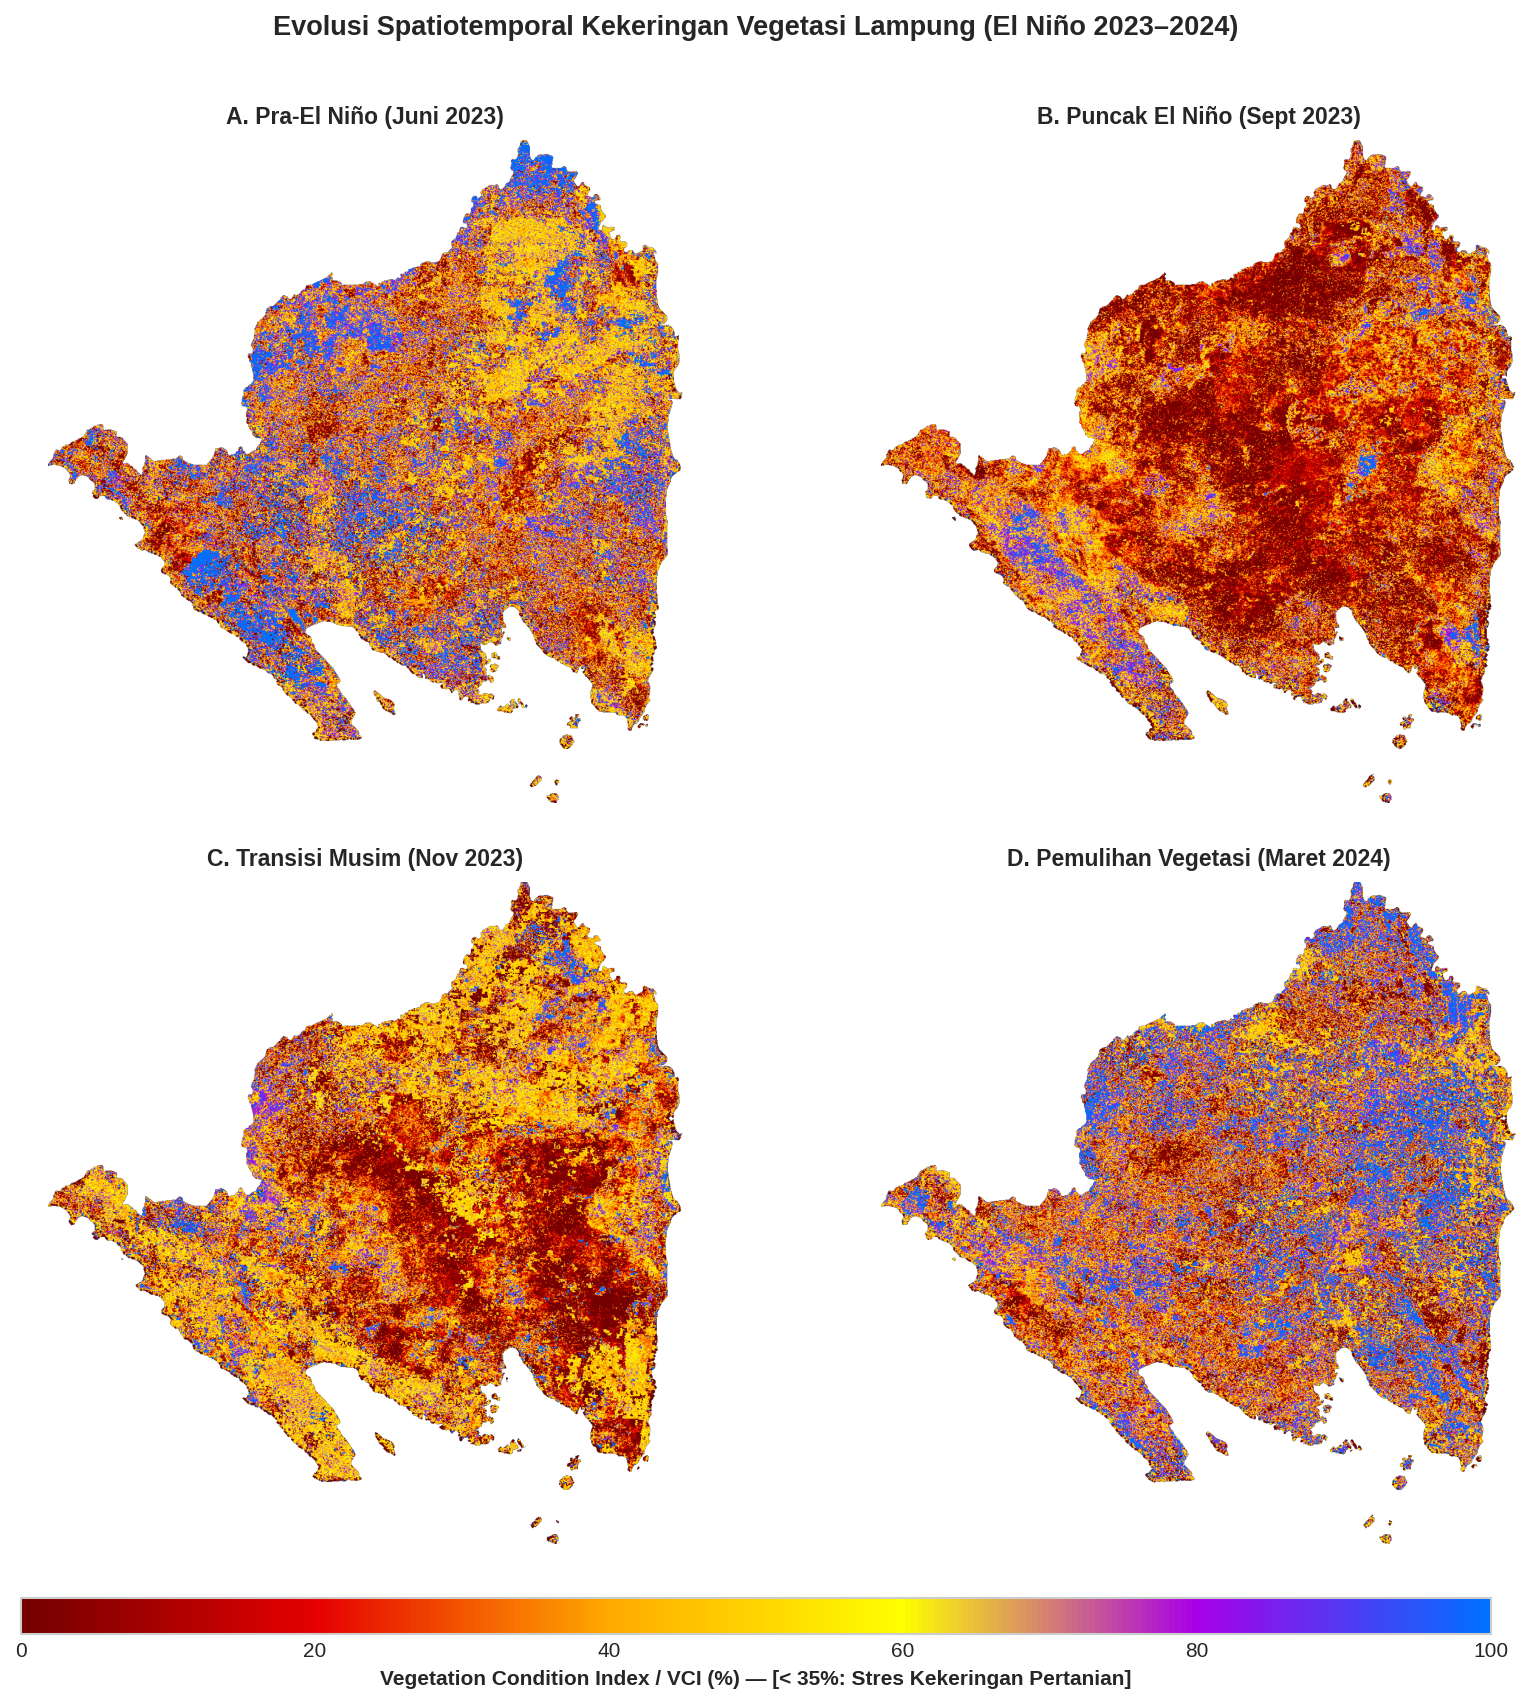

Peta 4-Panel berhasil disimpan ke: /content/drive/MyDrive/Agricultural_Drought_Lampung/VCI_Temporal_4Panel_Map.png


In [33]:
folder_path = '/content/drive/MyDrive/Agricultural_Drought_Lampung'
file_tif_vci = os.path.join(
    folder_path, 'MODIS_VCI_AllVegetation_Stack_2015_2025.tif'
)

# Jun 2023 (Awal), Sep 2023 (Puncak), Nov 2023 (Dampak Lanjutan), Mar 2024 (Pemulihan)
months_info = [
    {'year': 2023, 'month': 6, 'title': 'A. Pra-El Niño (Juni 2023)'},
    {'year': 2023, 'month': 9, 'title': 'B. Puncak El Niño (Sept 2023)'},
    {'year': 2023, 'month': 11, 'title': 'C. Transisi Musim (Nov 2023)'},
    {'year': 2024, 'month': 3, 'title': 'D. Pemulihan Vegetasi (Maret 2024)'},
]

cmap_vci = mcolors.LinearSegmentedColormap.from_list(
    'vci_cmap',
    ['#730000', '#e60000', '#ffaa00', '#ffff00', '#a800e6', '#0070ff'],
)

fig, axes = plt.subplots(2, 2, figsize=(14, 12), dpi=150)
axes = axes.flatten()

with rasterio.open(file_tif_vci) as src_vci:
  for idx, info in enumerate(months_info):
    band_idx = (info['year'] - 2015) * 12 + info['month']
    grid_vci = src_vci.read(band_idx)
    grid_vci = np.where((grid_vci < 0) | (grid_vci > 100), np.nan, grid_vci)

    ax = axes[idx]
    im = ax.imshow(grid_vci, cmap=cmap_vci, vmin=0, vmax=100)
    ax.set_title(info['title'], fontsize=11, fontweight='bold', pad=8)
    ax.axis('off')

# Colorbar Utama di Bagian Bawah
cbar_ax = fig.add_axes([0.15, 0.05, 0.7, 0.02])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label(
    'Vegetation Condition Index / VCI (%) — [< 35%: Stres Kekeringan'
    ' Pertanian]',
    fontsize=10,
    fontweight='bold',
)

plt.suptitle(
    'Evolusi Spatiotemporal Kekeringan Vegetasi Lampung (El Niño 2023–2024)',
    fontsize=13,
    fontweight='bold',
    y=0.95,
)
plt.subplots_adjust(wspace=0.05, hspace=0.12, bottom=0.1)

output_panel_path = os.path.join(folder_path, 'VCI_Temporal_4Panel_Map.png')
plt.savefig(output_panel_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Peta 4-Panel berhasil disimpan ke: {output_panel_path}')

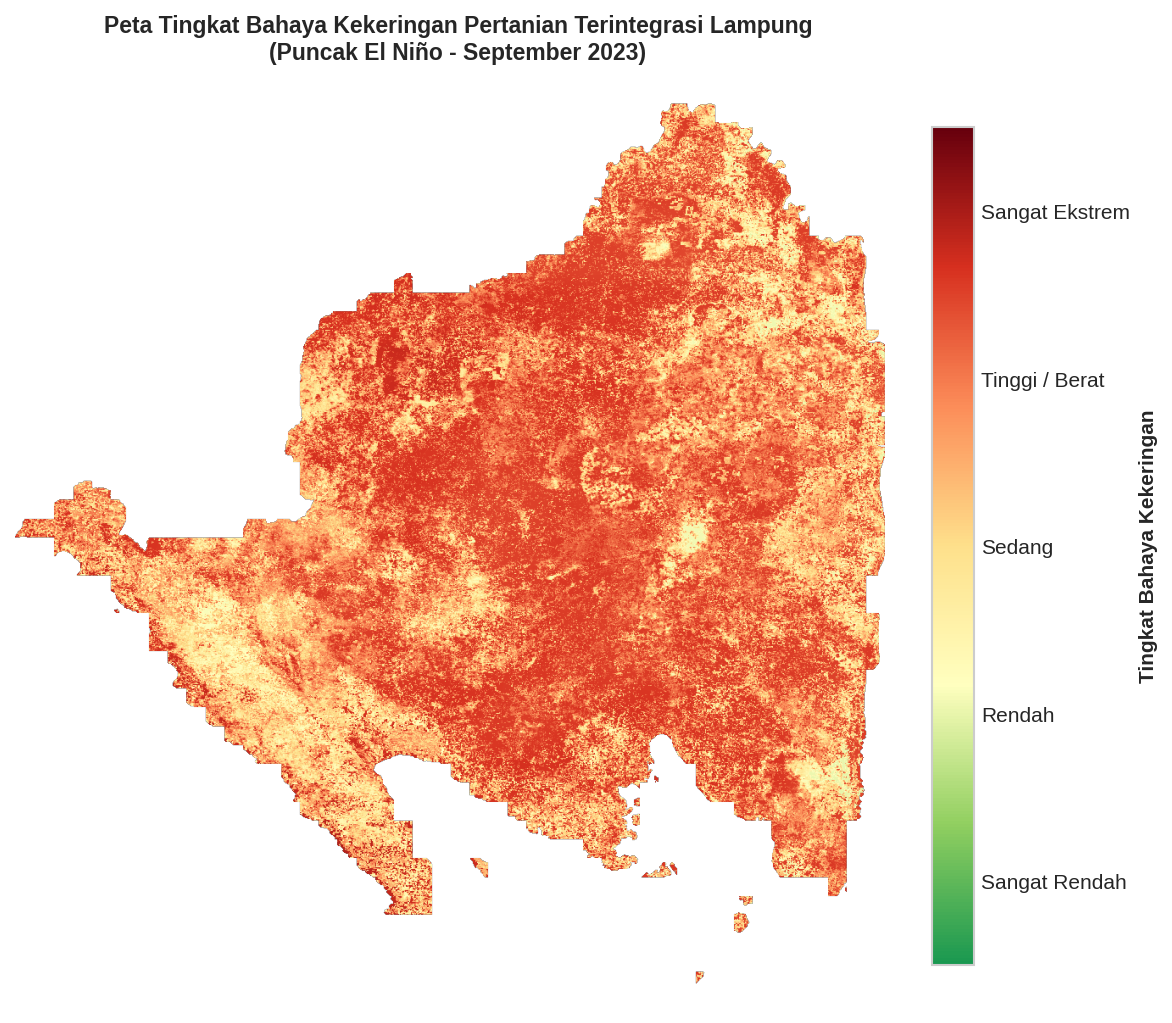

Peta Bahaya Terintegrasi berhasil disimpan ke: /content/drive/MyDrive/Agricultural_Drought_Lampung/Integrated_Drought_Hazard_Map_Sept2023.png


In [35]:
from rasterio.warp import reproject, Resampling
import numpy as np

# Peta Indeks Kekeringan Pertanian Terintegrasi (Single Composite)
file_tif_spi = os.path.join(folder_path, 'SPI3_Monthly_Stack_2015_2025.tif')
band_sept_2023 = (2023 - 2015) * 12 + 9

with rasterio.open(file_tif_spi) as src_spi, rasterio.open(
    file_tif_vci
) as src_vci:
  grid_spi_raw = src_spi.read(band_sept_2023) * -1.0
  grid_vci = src_vci.read(band_sept_2023).astype(np.float32)

  # Siapkan array kosong dengan ukuran yang sama dengan VCI
  grid_spi = np.empty(grid_vci.shape, dtype=np.float32)

  # Reproject (Resample) SPI agar ukurannya sama persis dengan VCI
  reproject(
      source=grid_spi_raw,
      destination=grid_spi,
      src_transform=src_spi.transform,
      src_crs=src_spi.crs,
      dst_transform=src_vci.transform,
      dst_crs=src_vci.crs,
      resampling=Resampling.bilinear
  )

  # Masking pixel invalid
  valid_mask = (
      (grid_spi > -10)
      & (grid_spi < 10)
      & (grid_vci >= 0)
      & (grid_vci <= 100)
  )

  # Hitung Indeks Komposit Risiko (0 - 100)
  # SPI Normalisasi (-2.5 s.d. +2.5 -> 0 s.d. 100)
  spi_norm = np.clip((grid_spi + 2.5) / 5.0 * 100.0, 0, 100)

  # Indeks Bahaya (Makin tinggi = Makin Ekstrem Kekeringan)
  drought_hazard = 0.5 * (100.0 - spi_norm) + 0.5 * (100.0 - grid_vci)
  drought_hazard = np.where(valid_mask, drought_hazard, np.nan)

# Palet Warna Klasifikasi Bahaya (Hijau -> Kuning -> Merah Tua)
cmap_hazard = mcolors.LinearSegmentedColormap.from_list(
    'hazard_cmap',
    ['#1a9850', '#91cf60', '#ffffbf', '#fee08b', '#fc8d59', '#d7301f', '#67000d'],
)

fig, ax = plt.subplots(figsize=(9, 8), dpi=150)
im = ax.imshow(drought_hazard, cmap=cmap_hazard, vmin=0, vmax=100)
ax.set_title(
    'Peta Tingkat Bahaya Kekeringan Pertanian Terintegrasi Lampung\n(Puncak El'
    ' Niño - September 2023)',
    fontsize=11,
    fontweight='bold',
    pad=12,
)
ax.axis('off')

# Colorbar dengan Label Klasifikasi
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
cbar.set_label('Tingkat Bahaya Kekeringan', fontsize=10, fontweight='bold')
cbar.set_ticks([10, 30, 50, 70, 90])
cbar.set_ticklabels(
    ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi / Berat', 'Sangat Ekstrem']
)

output_hazard_path = os.path.join(
    folder_path, 'Integrated_Drought_Hazard_Map_Sept2023.png'
)
plt.savefig(output_hazard_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Peta Bahaya Terintegrasi berhasil disimpan ke: {output_hazard_path}')